In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv("Loans_Dataset.csv")
df.head()

,initial_payment,last_payment,credit_score,house_number,sum,result
0,201,10018,250,3046,13515,yes
1,205,10016,395,3044,13660,yes
2,257,10129,109,3251,13746,yes
3,246,10064,324,3137,13771,yes
4,117,10115,496,3094,13822,yes


In [4]:
print("Dataset shape:", df.shape)
print("\\nColumn names:")
print(df.columns.tolist())
print("\\nDataset information:")
df.info()
display(df.describe(include="all"))
print("\\nMissing values in each column:")
print(df.isnull().sum())
print("\\nNumber of duplicate rows:", df.duplicated().sum())
print("\\nTarget variable counts:")
print(df["result"].value_counts())

Dataset shape: (1004, 6)
\nColumn names:
['initial_payment', 'last_payment', 'credit_score', 'house_number', 'sum', 'result']
\nDataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004 entries, 0 to 1003
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   initial_payment  1004 non-null   int64 
 1   last_payment     1004 non-null   int64 
 2   credit_score     1004 non-null   int64 
 3   house_number     1004 non-null   int64 
 4   sum              1004 non-null   int64 
 5   result           1004 non-null   object
dtypes: int64(5), object(1)
memory usage: 47.2+ KB


,initial_payment,last_payment,credit_score,house_number,sum,result
count,1004.000000,1004.000000,1004.000000,1004.000000,1004.000000,1004
unique,NaN,NaN,NaN,NaN,NaN,2
top,NaN,NaN,NaN,NaN,NaN,No
freq,NaN,NaN,NaN,NaN,NaN,521
mean,294.662351,12473.009960,528.902390,4041.282869,17744.012948,NaN
std,115.844218,1442.134231,259.681745,618.431417,9594.659715,NaN
min,100.000000,10005.000000,100.000000,3003.000000,13515.000000,NaN
25%,195.750000,11213.500000,302.750000,3546.500000,16081.250000,NaN
50%,290.000000,12467.000000,518.000000,4046.000000,17383.000000,NaN
75%,398.000000,13690.000000,755.000000,4508.750000,18608.250000,NaN


\nMissing values in each column:
initial_payment    0
last_payment       0
credit_score       0
house_number       0
sum                0
result             0
dtype: int64
\nNumber of duplicate rows: 0
\nTarget variable counts:
result
No     521
yes    483
Name: count, dtype: int64


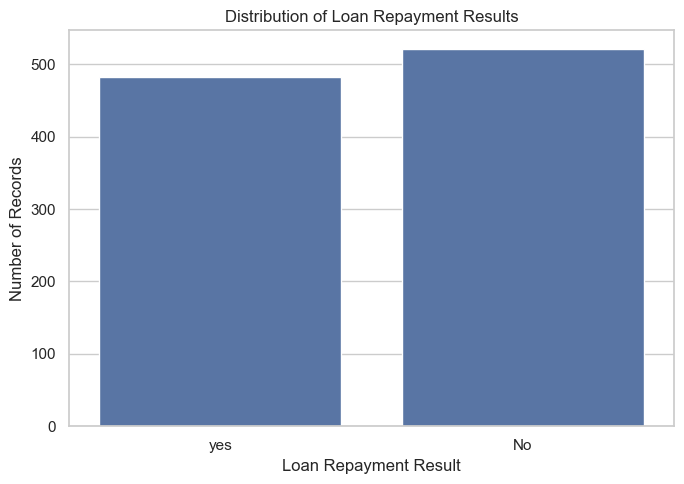

In [5]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="result")
plt.title("Distribution of Loan Repayment Results")
plt.xlabel("Loan Repayment Result")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

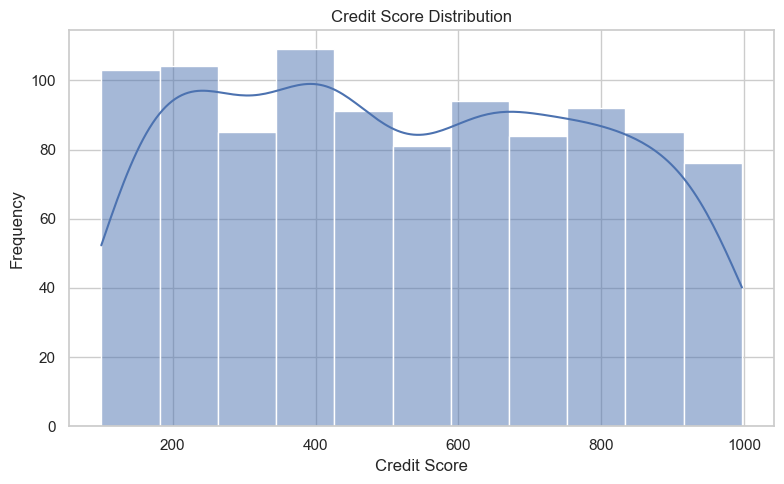

In [6]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="credit_score", kde=True)
plt.title("Credit Score Distribution")
plt.xlabel("Credit Score")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

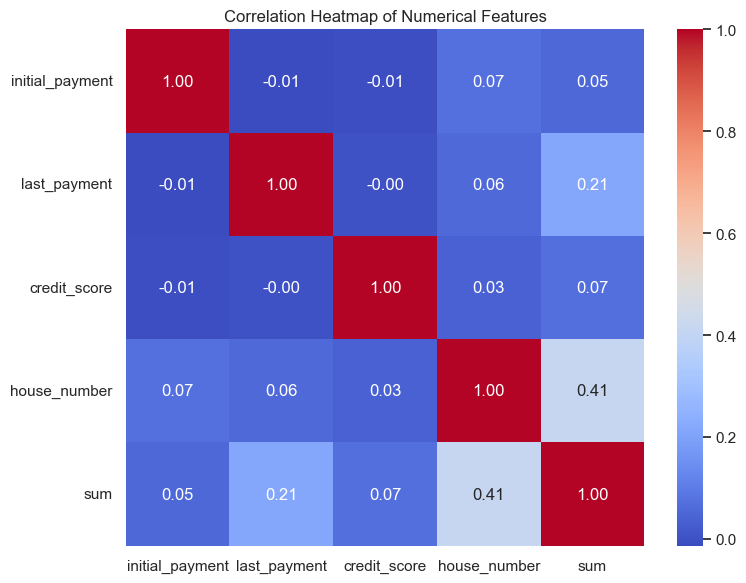

In [7]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.select_dtypes(include=np.number).corr(),
            annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

In [8]:
# Check missing values
print(df.isnull().sum())

# Remove duplicate rows if any are present
df = df.drop_duplicates().copy()

# Separate input features (X) and target variable (y)
X = df.drop(columns=["result"])
y = df["result"].astype(str).str.strip().str.lower()

print("Input features:", X.columns.tolist())
print("Target categories:", y.unique())

initial_payment    0
last_payment       0
credit_score       0
house_number       0
sum                0
result             0
dtype: int64
Input features: ['initial_payment', 'last_payment', 'credit_score', 'house_number', 'sum']
Target categories: ['yes' 'no']


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training feature rows:", X_train.shape[0])
print("Testing feature rows:", X_test.shape[0])

Training feature rows: 803
Testing feature rows: 201


In [12]:
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    random_state=42
)

model.fit(X_train, y_train)

print("Decision Tree model training completed.")

Decision Tree model training completed.


In [11]:
y_pred = model.predict(X_test)

print("Predicted values:")
print(y_pred[:20])

Predicted values:
['yes' 'no' 'yes' 'yes' 'yes' 'yes' 'no' 'yes' 'yes' 'yes' 'yes' 'yes'
 'no' 'no' 'yes' 'no' 'yes' 'no' 'yes' 'yes']


In [13]:
accuracy = accuracy_score(y_test, y_pred)
print("Model Accuracy: {:.2f}%".format(accuracy * 100))

Model Accuracy: 100.00%


Confusion Matrix:
[[104   0]
 [  0  97]]


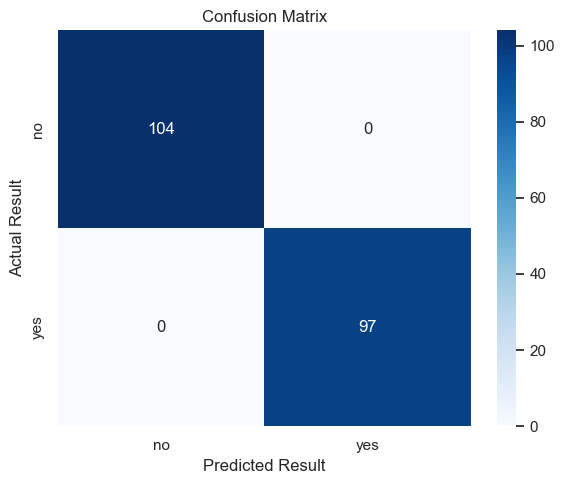

In [14]:
labels = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")
plt.tight_layout()
plt.show()

In [15]:
print(classification_report(y_test, y_pred, zero_division=0))

              precision    recall  f1-score   support

          no       1.00      1.00      1.00       104
         yes       1.00      1.00      1.00        97

    accuracy                           1.00       201
   macro avg       1.00      1.00      1.00       201
weighted avg       1.00      1.00      1.00       201



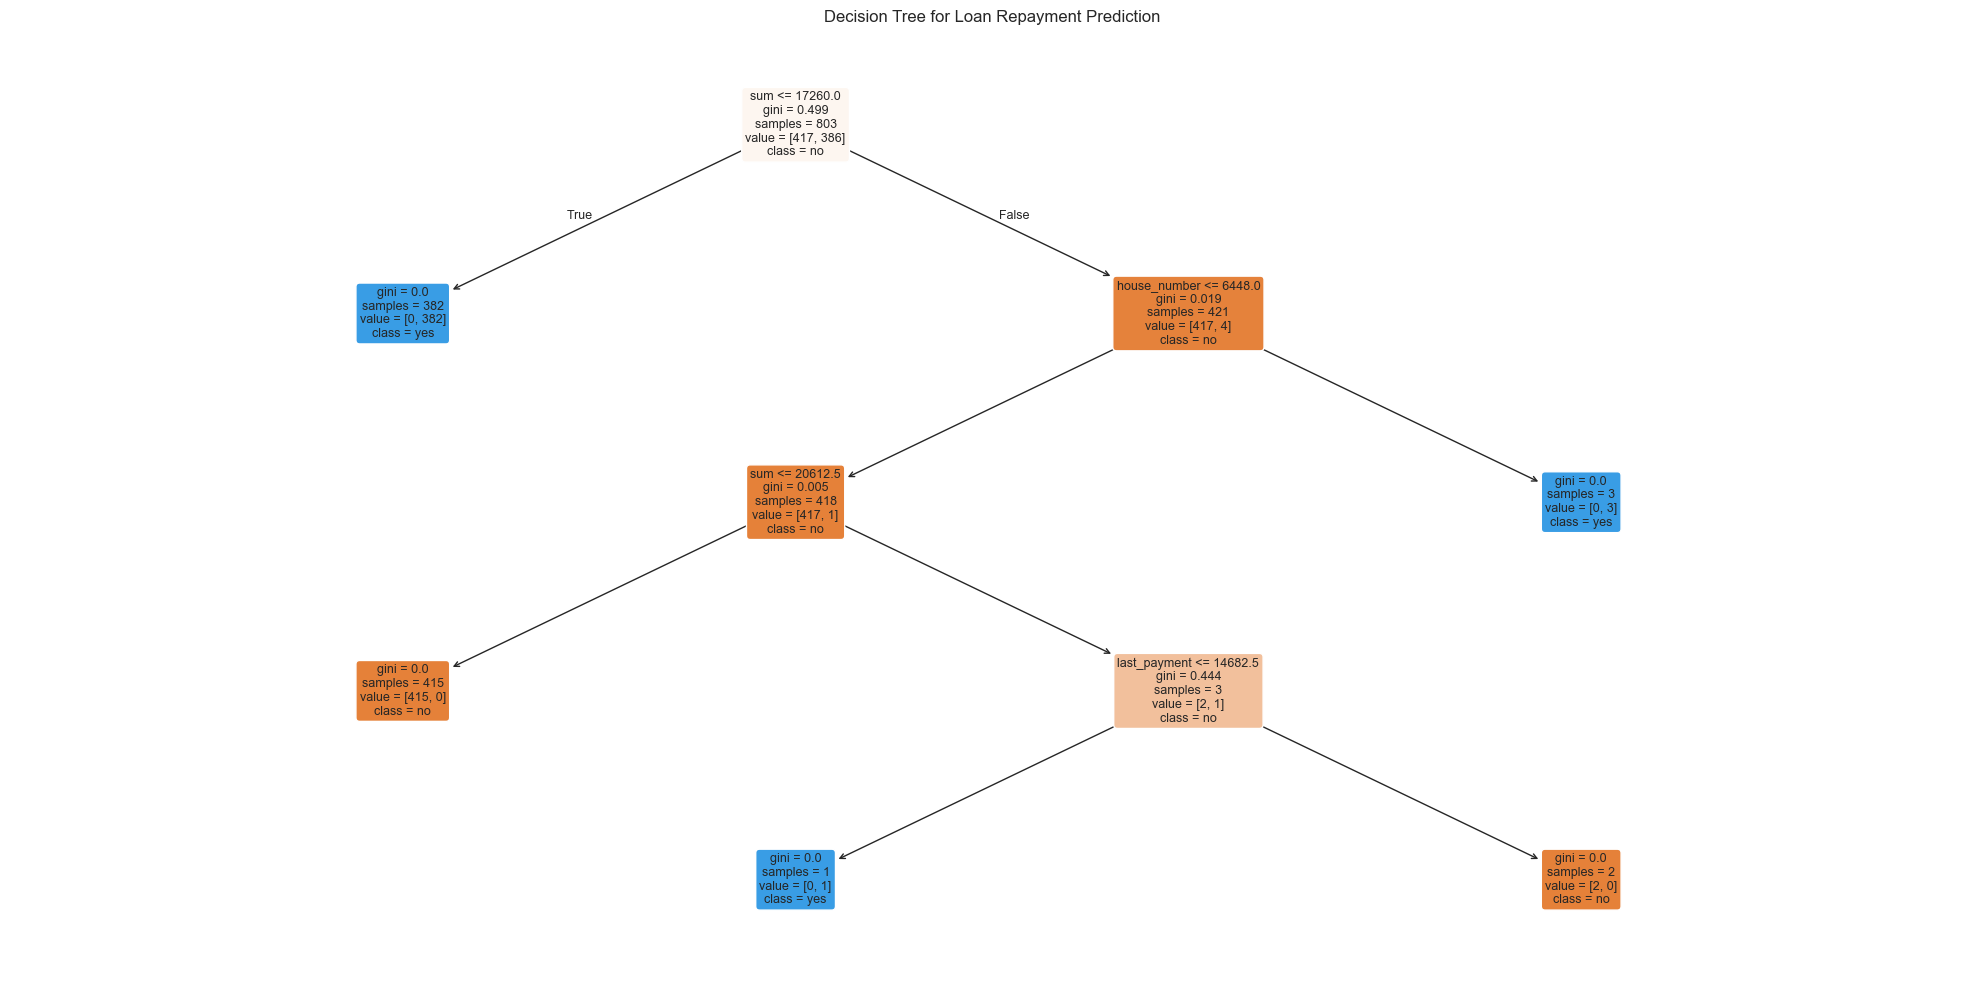

In [16]:
plt.figure(figsize=(20, 10))
plot_tree(
    model,
    feature_names=X.columns,
    class_names=[str(c) for c in model.classes_],
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("Decision Tree for Loan Repayment Prediction")
plt.tight_layout()
plt.show()

count      1004.000000
mean      17744.012948
std        9594.659715
min       13515.000000
25%       16081.250000
50%       17383.000000
75%       18608.250000
max      246789.000000
Name: sum, dtype: float64


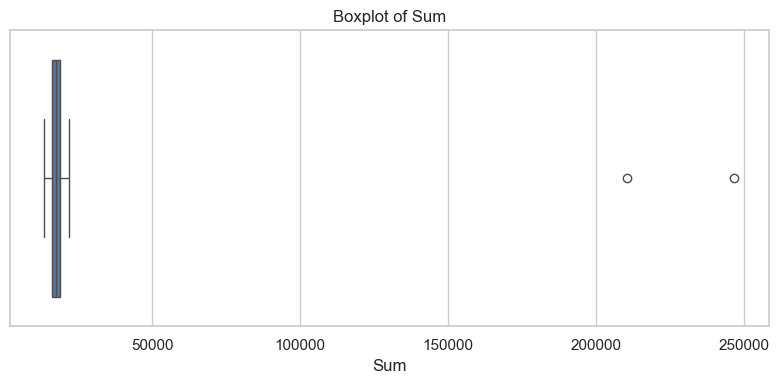

Rows where sum differs from the other four features' total: 4


In [17]:
print(df["sum"].describe())

plt.figure(figsize=(8, 4))
sns.boxplot(x=df["sum"])
plt.title("Boxplot of Sum")
plt.xlabel("Sum")
plt.tight_layout()
plt.show()
feature_total = df[
    ["initial_payment", "last_payment", "credit_score", "house_number"]
].sum(axis=1)

print("Rows where sum differs from the other four features' total:",
      (df["sum"] != feature_total).sum())